# Face Mask Detection (4/10/26)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("omkargurav/face-mask-dataset")

print("Path to dataset files:", path)

100%|██████████| 163M/163M [00:01<00:00, 162MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1


In [2]:
import os
print(os.listdir(path))

['data']


In [3]:
!pip install split-folders -q

In [4]:
import splitfolders

## Dividing the Whole Data into Train, Test & Validation

In [5]:
splitfolders.ratio("/root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1/data", ratio=(0.7,0.2,0.1), output="Gun_detection")

Copying files: 7553 files [00:02, 3424.67 files/s]


# Preprocessing Images

In [6]:
import tensorflow as tf

In [7]:
train_data = tf.keras.utils.image_dataset_from_directory(
    "/content/Gun_detection/train",
    image_size=(128,128),
    batch_size=32,
    seed=42
)

Found 5286 files belonging to 2 classes.


In [8]:
test_data = tf.keras.utils.image_dataset_from_directory(
    "/content/Gun_detection/test",
    image_size=(128,128),
    batch_size=32,
    seed=42
)

Found 757 files belonging to 2 classes.


In [9]:
val_data = tf.keras.utils.image_dataset_from_directory(
    "/content/Gun_detection/val",
    image_size=(128,128),
    batch_size=32,
    seed=42
)

Found 1510 files belonging to 2 classes.


In [10]:
from PIL import Image
import cv2
from IPython import display

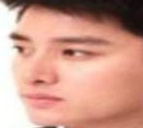

In [11]:
Image.open("/content/Gun_detection/test/without_mask/without_mask_1090.jpg")

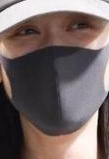

In [12]:
Image.open("/content/Gun_detection/train/with_mask/with_mask_1007.jpg")

array([[[89, 82, 87],
        [68, 62, 67],
        [44, 39, 48],
        ...,
        [26, 28, 28],
        [31, 33, 34],
        [38, 40, 41]],

       [[78, 71, 76],
        [63, 56, 63],
        [52, 47, 56],
        ...,
        [19, 21, 21],
        [24, 26, 27],
        [29, 31, 32]],

       [[76, 68, 75],
        [64, 57, 64],
        [67, 62, 71],
        ...,
        [27, 29, 29],
        [22, 24, 25],
        [23, 25, 26]],

       ...,

       [[23, 25, 33],
        [13, 15, 23],
        [19, 19, 25],
        ...,
        [12, 10, 10],
        [12, 10, 10],
        [13, 11, 11]],

       [[23, 25, 33],
        [13, 15, 23],
        [19, 19, 25],
        ...,
        [13, 11, 11],
        [15, 13, 13],
        [17, 15, 15]],

       [[23, 25, 33],
        [13, 15, 23],
        [19, 19, 25],
        ...,
        [14, 12, 12],
        [15, 13, 13],
        [16, 14, 14]]], dtype=uint8)
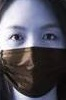

In [13]:
cv2.imread("/content/Gun_detection/train/with_mask/with_mask_1079.jpg")

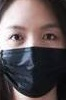

In [14]:
display.Image("/content/Gun_detection/train/with_mask/with_mask_1079.jpg")

In [15]:
from tensorflow import keras
from tensorflow.keras import layers , Sequential

### Neurons Layers Architecture

In [16]:
model = keras.Sequential([
    layers.Conv2D(32, (3,3), padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), padding="same"), #Feature Extract
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid") # Output Layer with 1 Output & Sigmoid 0 or 1 Probability


])

In [17]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [18]:
model.fit(train_data, epochs=30, validation_data=val_data)

Epoch 1/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - accuracy: 0.5023 - loss: 13.9256 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 2/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 3/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 4/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 5/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 6/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 7/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5066 - val_loss: 0.6931
Epoch 8/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.5068 - loss: 0.6931 - val_a

# Gradio:

- Gradio is an open-source Python library that lets you build interactive web interfaces and demos for machine learning models or general Python functions using only Python code.

In [19]:
import numpy as np

In [20]:
import gradio as gr

In [21]:
def predict_image(img):
    img = img.resize((128,128))
    # img = tf.expand_dims(img, 0)
    img = np.expand_dims(np.array(img), axis=0)
    # img_array = tf.keras.utils.img_to_array(images[i].numpy())
    prediction = model.predict(img)[0][0]

    if prediction < 0.5:
      return "Masked"

    else:
      return "No Mask"

app = gr.Interface(fn = predict_image, inputs=gr.Image(type="pil"), outputs="text")

In [24]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2)
])

In [25]:
model = keras.Sequential([
    data_augmentation,

    layers.Rescaling(1./255),
    layers.Conv2D(32, (3,3), padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), padding="same"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), padding="same"), #Feature Extract
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid") # Output Layer with 1 Output & Sigmoid 0 or 1 Probability


])

In [26]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [27]:
model.fit(train_data, epochs=30, validation_data=val_data)

Epoch 1/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 16s 50ms/step - accuracy: 0.7785 - loss: 0.5501 - val_accuracy: 0.8629 - val_loss: 0.3403
Epoch 2/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.8451 - loss: 0.3913 - val_accuracy: 0.8762 - val_loss: 0.2931
Epoch 3/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.8704 - loss: 0.3345 - val_accuracy: 0.8781 - val_loss: 0.2852
Epoch 4/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.8704 - loss: 0.3237 - val_accuracy: 0.8748 - val_loss: 0.2842
Epoch 5/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.8759 - loss: 0.3088 - val_accuracy: 0.8848 - val_loss: 0.2748
Epoch 6/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.8759 - loss: 0.2996 - val_accuracy: 0.8808 - val_loss: 0.2833
Epoch 7/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.8865 - loss: 0.2876 - val_accuracy: 0.8927 - val_loss: 0.2536
Epoch 8/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.8842 - loss: 0.2750 - val_

In [28]:
def predict_image(img):
    img = img.resize((128,128))
    # img = tf.expand_dims(img, 0)
    img = np.expand_dims(np.array(img), axis=0)
    # img_array = tf.keras.utils.img_to_array(images[i].numpy())
    prediction = model.predict(img)[0][0]

    if prediction < 0.5:
      return "Masked"

    else:
      return "No Mask"

app = gr.Interface(fn = predict_image, inputs=gr.Image(type="pil"), outputs="text")

In [29]:
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bb43a6085d5e2f1b23.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [31]:
# import shutil

# shutil.copytree(
#     "/content/Gun_detection",
#     "/content/drive/MyDrive/SMIT/Deep Learning/04_Face_Mask_Detection/Gun_detection",
#     dirs_exist_ok=True
# )


In [32]:
model.save("/content/drive/MyDrive/SMIT/Deep Learning/06_Face_Mask_Detection/mask_model.keras")

In [34]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/SMIT/Deep Learning/06_Face_Mask_Detection/mask_model.keras")